#### 1. Setup

In [ ]:
from dotenv import load_dotenv
import os

load_dotenv()

In [ ]:
os.getenv("GROQ_API_KEY")

In [ ]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")

In [ ]:
res = llm.invoke("Hello !")
res.content

#### 2. State - Global State to pass the data b/a all the nodes

In [ ]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    email: str = ""
    age: int = 0
    
state = UserState(name="Prateek")

In [ ]:
state

##### 2.1 Building the Graph Using Langgraph

In [ ]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    messages: str = ""
    isPassed: bool = False
    
def greet(state:MyState):
    "I am greet node..."
    state.isPassed = True
    state.messages = "Googmorning !"
    return state

graph = StateGraph(MyState)
graph.add_node("welcome", greet)

graph.add_edge(START, "welcome")
graph.add_edge("welcome", END)

final_graph = graph.compile()
    

In [ ]:
final_graph

In [ ]:
res = final_graph.invoke({"messages": "HEllo, Hows you ?"})

In [ ]:
res

##### 2.2 Multi Node Graph

In [ ]:
from random import randint

class ReviewState(BaseModel):
    text: str = ""
    score: int = 0
    comments: str = ""
    

def score(state:ReviewState) -> ReviewState:
    state.score = randint(1, 10)
    return state


def commenter(state:ReviewState) -> ReviewState:
    if state.score > 5:
        state.comments = "Well Done"
    else:
        state.comments = "Need Improvement"
    return state


graph = StateGraph(ReviewState)
graph.add_node("score", score)
graph.add_node("commenter", commenter)

graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

final_graph = graph.compile()

In [ ]:
final_graph

In [ ]:
res = final_graph.invoke({})

In [ ]:
res

#### 3. `add_messages` reducer - for chat history

In [ ]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated

def custom_reducer(existing: list, new: list):
    all_msg = existing + new
    return all_msg[-1:]

def isPositive(existing:int, new:int):
    if new < 0:
        return 0
    return new
    

class ChatState(BaseModel):
    messages: Annotated[list, custom_reducer] = []
    count : Annotated[int, isPositive] = 0
    


def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    state.count = -10
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile()


In [ ]:
final_graph

In [ ]:
res = final_graph.invoke({"messages": [ HumanMessage(content="Hello, HoWS YOU ?") ]})

In [ ]:
res

#### 4. Routing - Langgraph Core Component

In [ ]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Literal

class TicketState(BaseModel):
    issue:str = ""
    category: str = ""
    response: str = ""
    

def classify(state:TicketState) -> TicketState:
    issue = state.issue.lower()
    if "payment" in issue or "amount" in issue:
        state.category = "billing"
    elif "refund" in issue or "cancel" in issue:
        state.category = "refund"
    else:
        state.category = "status"

    return state


def handle_billing(state:TicketState) -> TicketState:
    print('Billing Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_refund(state:TicketState) -> TicketState:
    print('Refund Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_status(state:TicketState) -> TicketState:
    print('Status Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state
        

### This is not my node ?
def router_logic(state:TicketState) -> Literal["billing", "refund", "status"]:
    return state.category


graph = StateGraph(TicketState)
graph.add_node("classify", classify)
graph.add_node("handle_billing", handle_billing)
graph.add_node("handle_refund", handle_refund)
graph.add_node("handle_status", handle_status)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", router_logic, 
                    {"billing": "handle_billing", 
                    "status": "handle_status", 
                    "refund": "handle_refund"} 
                            )
graph.add_edge("handle_billing", END)
graph.add_edge("handle_refund", END)
graph.add_edge("handle_status", END)

final_graph = graph.compile()
final_graph    

In [ ]:
res = final_graph.invoke({"issue": "I am waiting for my rund "})

In [ ]:
res

#### 5. memory - checkpointer

In [90]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Annotated
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage


class ChatState(BaseModel):
    messages: Annotated[list, add_messages]
    
def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

memory = InMemorySaver()
final_graph = graph.compile(checkpointer=memory)

In [ ]:
res = final_graph.invoke(
        {"messages": 
            [ HumanMessage(content="What is his age ?") ]
            },
        {"configurable": {"thread_id":"asd1"}}
    )
ans = res["messages"][-1].content
print(ans)

In [ ]:
# %pip install langgraph-checkpoint-sqlite

In [ ]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect("db.sqlite3", check_same_thread=False)
sql_memory = SqliteSaver(connection)
sql_memory.setup()


In [ ]:
sqlite_graph = graph.compile(checkpointer=sql_memory)

In [ ]:
res = sqlite_graph.invoke(
        {"messages": 
            [ HumanMessage(content="What is his age ?") ]
            },
        {"configurable": {"thread_id":"asd1"}}
    )
ans = res["messages"][-1].content
print(ans)

#### 6. Agents and Tools - ToolNodes

In [53]:
#### We need to define the tools
from langchain.tools import tool

@tool
def weather_tool(city:str) -> str:
    """
        Get the real time weather details for any city.
        Args: 
            city - city name for the weather details
    """
    ### Real weather api call
    data = {
        "bhopal":"32",
        "delhi": "38",
        "mumbai": "36"
    }
    
    return "34"
    

@tool
def calculate(expression:str):
    """
        Execute the math equations : Ex. '4 * 4 - 4'
    """
    try: 
        return eval(expression)
    except:
        return "Please provide the correct expression"

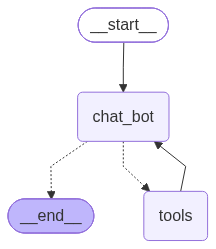

In [54]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import tools_condition, ToolNode

class AgentState(BaseModel):    
    messages: Annotated[list, add_messages]
    
tools = [weather_tool, calculate]
llm_with_tools = llm.bind_tools(tools)

def chat_bot(state:AgentState):
    res = llm_with_tools.invoke(state.messages)
    state.messages = [res]
    return state


tool_node = ToolNode(tools)

graph = StateGraph(AgentState)
graph.add_node("chat_bot", chat_bot)
graph.add_node("tools", tool_node)


graph.add_edge(START, "chat_bot")
graph.add_conditional_edges("chat_bot", tools_condition)
graph.add_edge("tools", "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile(checkpointer=sql_memory)

final_graph
    

In [55]:
res = final_graph.invoke(
        {"messages": 
            [ HumanMessage(content="WHat is the temperature in Mumbai ?") ]
            },
        {"configurable": {"thread_id":"asd10"}}
    )
ans = res["messages"][-1].content

In [ ]:
# for msg in res["messages"]:
#     msg.pretty_print()

In [56]:
res["messages"][-1].content

'The current temperature in Mumbai is **34\u202f°C**.'

#### 7. Human-In-The-Loop

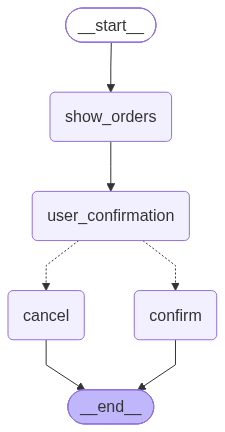

In [58]:
from pydantic import BaseModel
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

class PurchaseState(BaseModel):
    item:str = ""
    price: int = 0
    confirmed: bool = False
    status:str = ""
    
def show_orders(state:PurchaseState) -> PurchaseState:
    print(f"Order Summary: Product: {state.item} & Price: {state.price}")
    return state


def user_confirmation(state:PurchaseState) -> PurchaseState:
    response = interrupt(
        {
            "question":f"Confirm your purchase for {state.item} and price is: {state.price}. Please reply in Yes or No."
        }
    )
    
    state.confirmed = response.lower() == "yes"
    return state
    
    
def order_cancel(state:PurchaseState) -> PurchaseState:
    print("We have canceled you order. Thanks")
    return state


def order_confirm(state:PurchaseState) -> PurchaseState:
    print("You successfully placed your order...")
    return state
    
    
## this is not my node    
def router(state:PurchaseState) -> Literal["cancel", "confirm"]:
    if state.confirmed:
        return "confirm"
    return "cancel"


graph = StateGraph(PurchaseState)
graph.add_node("show_orders", show_orders)
graph.add_node("user_confirmation", user_confirmation)
graph.add_node("cancel", order_cancel)
graph.add_node("confirm", order_confirm)

graph.add_edge(START, "show_orders")
graph.add_edge("show_orders", "user_confirmation")
graph.add_conditional_edges("user_confirmation", router)
graph.add_edge("cancel", END)
graph.add_edge("confirm", END)

final_graph = graph.compile(checkpointer=InMemorySaver())
final_graph
    

In [70]:
res = final_graph.invoke(
        {"item": "Samsung S23", "price":12000},
        {"configurable": {"thread_id":"asd10"}}
    )

print(res["__interrupt__"][0].value["question"])

Order Summary: Product: Samsung S23 & Price: 12000
Confirm your purchase for Samsung S23 and price is: 12000. Please reply in Yes or No.


In [72]:
#### Confirm the Purchase Order
res = final_graph.invoke(
        Command(resume="no"),
        {"configurable": {"thread_id":"asd10"}}
    )

We have canceled you order. Thanks


In [73]:
res

{'item': 'Samsung S23', 'price': 12000, 'confirmed': False, 'status': ''}

#### 8. Parallel Operations - Nodes

In [91]:
DOCUMENTS = [
    {"id": 1, "text": "LangGraph is a library for building stateful, multi-actor applications with LLMs."},
    {"id": 2, "text": "Python is a high-level programming language known for its simple syntax and readability."},
    {"id": 3, "text": "Machine learning enables systems to learn from data automatically."},
]

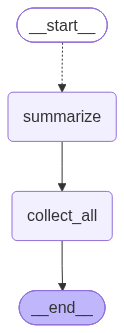

In [111]:
import operator
from datetime import datetime
from typing import Annotated
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, Overwrite

def custom_reducer(existing: list, new: list):
    return existing + new

class SummarizerState(BaseModel):
    documents: list[dict] = []
    summaries: Annotated[list, custom_reducer]
    
class Document(BaseModel):
    id: int = 0
    text: str = ""

def route_to_summarizer(state: SummarizerState):
    sends = []
    for doc in state.documents:
        document = Document(id = doc["id"], text=doc["text"])
        sends.append(Send("summarize", document))
        
    return sends


def summarize(state:Document):
    now = datetime.now()
    print("\n Summarize Node...", now.strftime("%M:%S"))
    response = llm.invoke(f"Summarize is 5 Words: {state.text}")
    return {"summaries": [ {"id": state.id, "summary": response.content.strip()} ]}


def collect_all(state:SummarizerState):
    print("All Summaries: ", state.summaries)
    return {}

graph = StateGraph(SummarizerState)
graph.add_node("summarize", summarize)
graph.add_node("collect_all", collect_all)

graph.add_conditional_edges(START, route_to_summarizer, ["summarize"])
graph.add_edge("summarize", "collect_all")
graph.add_edge("collect_all", END)

final_graph = graph.compile(checkpointer=memory)
final_graph


In [112]:
res = final_graph.invoke({"documents": DOCUMENTS, "summaries": Overwrite([])}, {"configurable": {"thread_id":"asd10"}})


 Summarize Node...
 Summarize Node... 54:09

 Summarize Node... 54:09
 54:09
All Summaries:  [{'id': 1, 'summary': 'Library for stateful multi‑actor LLMs.'}, {'id': 2, 'summary': 'Python: readable, simple, high-level language.'}, {'id': 3, 'summary': 'ML lets systems learn autonomously.'}]
